<a href="https://colab.research.google.com/github/1322vishav/Image-Processing/blob/main/Assignment11/Task2_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget -q http://cs231n.stanford.edu/tiny-imagenet-200.zip
!unzip -q tiny-imagenet-200.zip

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

ROOT = '/content/tiny-imagenet-200'
wanted = ['goldfish', 'monarch', 'school bus']

names = {}
for line in open(f'{ROOT}/words.txt'):
    wnid, desc = line.strip().split('\t')
    names[wnid] = desc

train_wnids = sorted(os.listdir(f'{ROOT}/train'))
class_ids = []
for w in wanted:
    match = [i for i in train_wnids if names[i].lower().startswith(w)]
    class_ids.append(match[0])

class_names = [names[i].split(',')[0] for i in class_ids]
print(dict(zip(class_ids, class_names)))

X, y = [], []
for label, wnid in enumerate(class_ids):
    folder = f'{ROOT}/train/{wnid}/images'
    files = sorted(os.listdir(folder))[:200]
    for f in files:
        img = Image.open(os.path.join(folder, f)).convert('RGB')
        X.append(np.array(img))
        y.append(label)

X = np.array(X, dtype=np.float32)
y = np.array(y)
print(X.shape, y.shape, np.bincount(y))

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

{'n01443537': 'goldfish', 'n02279972': 'monarch', 'n04146614': 'school bus'}
(600, 64, 64, 3) (600,) [200 200 200]
(420, 64, 64, 3) (90, 64, 64, 3) (90, 64, 64, 3)


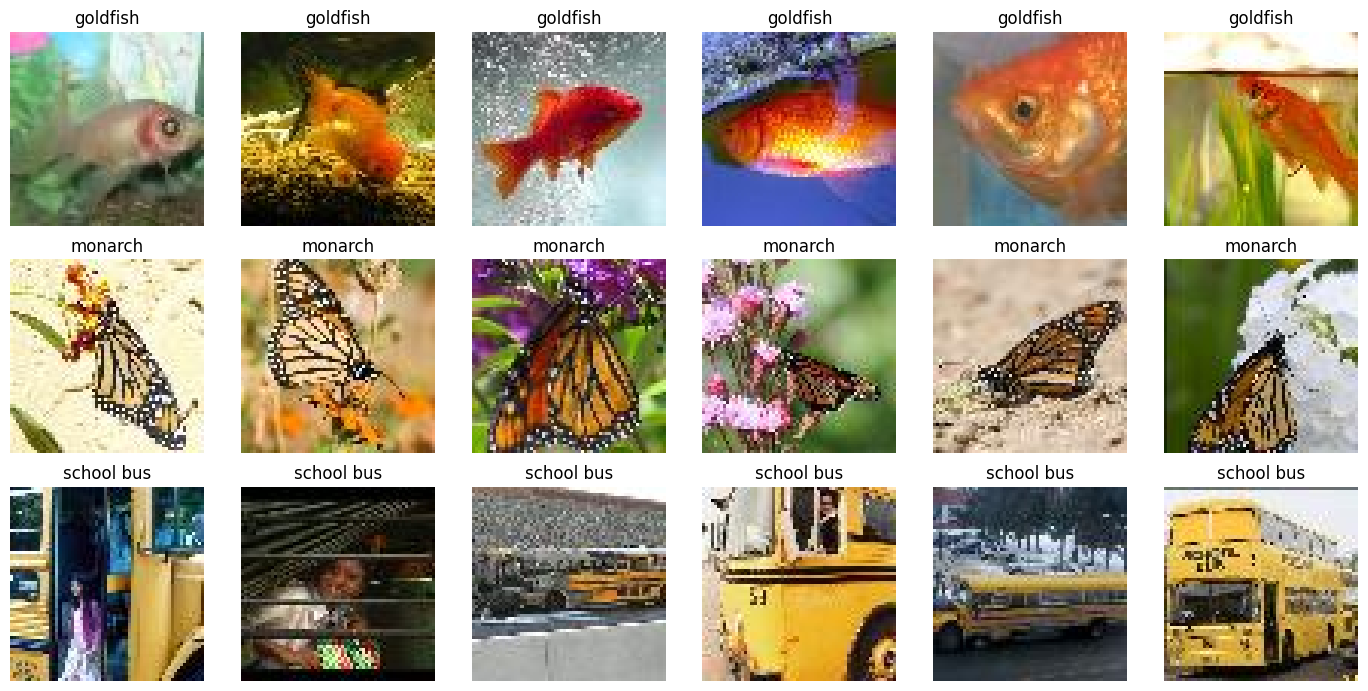

In [3]:
fig, ax = plt.subplots(3, 6, figsize=(14, 7))
for c in range(3):
    idx = np.where(y == c)[0][:6]
    for j, i in enumerate(idx):
        ax[c, j].imshow(X[i].astype(np.uint8))
        ax[c, j].set_title(class_names[c])
        ax[c, j].axis('off')
plt.tight_layout()
plt.show()

In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(model, X_eval, y_eval):
    pred = model.predict(X_eval, verbose=0).argmax(axis=1)
    return {
        'Accuracy': accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred, average='macro', zero_division=0),
        'Recall': recall_score(y_eval, pred, average='macro', zero_division=0),
        'F1': f1_score(y_eval, pred, average='macro', zero_division=0),
    }

results = {}

In [5]:
def build_cnn():
    return keras.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(3, activation='softmax'),
    ])

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,235 (4.36 MB)

 Trainable params: 1,142,787 (4.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = cnn.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=60, batch_size=32,
                  callbacks=[stop], verbose=2)

Epoch 1/60
14/14 - 27s - 2s/step - accuracy: 0.5619 - loss: 3.0228 - val_accuracy: 0.3889 - val_loss: 1.0455
Epoch 2/60
14/14 - 0s - 17ms/step - accuracy: 0.7976 - loss: 0.8165 - val_accuracy: 0.3333 - val_loss: 1.4216
Epoch 3/60
14/14 - 0s - 18ms/step - accuracy: 0.8595 - loss: 0.4048 - val_accuracy: 0.3333 - val_loss: 1.5366
Epoch 4/60
14/14 - 0s - 16ms/step - accuracy: 0.9095 - loss: 0.2847 - val_accuracy: 0.3333 - val_loss: 2.3600
Epoch 5/60
14/14 - 0s - 16ms/step - accuracy: 0.9310 - loss: 0.2034 - val_accuracy: 0.3333 - val_loss: 2.9945
Epoch 6/60
14/14 - 0s - 15ms/step - accuracy: 0.9429 - loss: 0.1636 - val_accuracy: 0.3333 - val_loss: 3.4010
Epoch 7/60
14/14 - 0s - 16ms/step - accuracy: 0.9500 - loss: 0.1303 - val_accuracy: 0.3333 - val_loss: 4.4111
Epoch 8/60
14/14 - 0s - 15ms/step - accuracy: 0.9595 - loss: 0.1155 - val_accuracy: 0.3333 - val_loss: 4.2492
Epoch 9/60
14/14 - 0s - 18ms/step - accuracy: 0.9548 - loss: 0.1310 - val_accuracy: 0.3333 - val_loss: 4.2781
Epoch 10/60

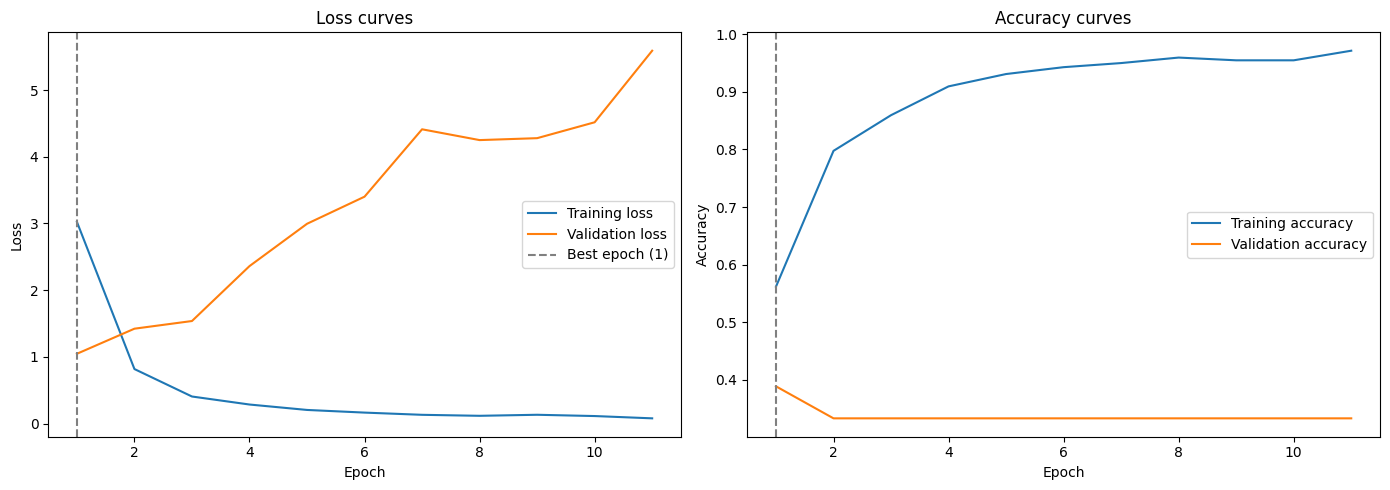

Epochs run: 11, best epoch: 1
Final train loss 0.0775 | val loss 5.5893 | gap 5.5118
Final train acc  0.9714 | val acc  0.3333 | gap 0.6381
Verdict: overfitting (training performance is much better than validation)


In [7]:
h = history.history
best_epoch = int(np.argmin(h['val_loss'])) + 1
epochs = range(1, len(h['loss']) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(epochs, h['loss'], label='Training loss')
ax[0].plot(epochs, h['val_loss'], label='Validation loss')
ax[0].axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].set_title('Loss curves')
ax[0].legend()

ax[1].plot(epochs, h['accuracy'], label='Training accuracy')
ax[1].plot(epochs, h['val_accuracy'], label='Validation accuracy')
ax[1].axvline(best_epoch, color='gray', linestyle='--')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].set_title('Accuracy curves')
ax[1].legend()
plt.tight_layout()
plt.show()

tr_acc, va_acc = h['accuracy'][-1], h['val_accuracy'][-1]
tr_loss, va_loss = h['loss'][-1], h['val_loss'][-1]
print(f"Epochs run: {len(epochs)}, best epoch: {best_epoch}")
print(f"Final train loss {tr_loss:.4f} | val loss {va_loss:.4f} | gap {va_loss - tr_loss:.4f}")
print(f"Final train acc  {tr_acc:.4f} | val acc  {va_acc:.4f} | gap {tr_acc - va_acc:.4f}")

if tr_acc < 0.65 and va_acc < 0.65:
    print("Verdict: underfitting (both training and validation performance are low)")
elif tr_acc - va_acc > 0.15 or va_loss - tr_loss > 0.3:
    print("Verdict: overfitting (training performance is much better than validation)")
else:
    print("Verdict: good fit (training and validation are close)")

In [8]:
results['Custom CNN'] = evaluate(cnn, X_test, y_test)
print({k: round(v, 4) for k, v in results['Custom CNN'].items()})

{'Accuracy': 0.3667, 'Precision': 0.2175, 'Recall': 0.3667, 'F1': 0.2323}


In [9]:
import cv2
from tensorflow.keras.applications import VGG16, MobileNet, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_pre
from tensorflow.keras.applications.mobilenet import preprocess_input as mob_pre
from tensorflow.keras.applications.resnet50 import preprocess_input as res_pre

SIZE = 128

def resize_all(arr):
    out = np.array([cv2.resize(a, (SIZE, SIZE), interpolation=cv2.INTER_CUBIC) for a in arr])
    return np.clip(out, 0, 255).astype(np.float32)

Xtr_r = resize_all(X_train)
Xva_r = resize_all(X_val)
Xte_r = resize_all(X_test)

configs = {
    'VGG16': (VGG16, vgg_pre),
    'MobileNet': (MobileNet, mob_pre),
    'ResNet50': (ResNet50, res_pre),
}

def build_transfer(base_cls):
    base = base_cls(weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3))
    base.trainable = False
    inputs = keras.Input(shape=(SIZE, SIZE, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(3, activation='softmax')(x)
    return keras.Model(inputs, outputs)

In [10]:
histories = {}

for name, (cls, pre) in configs.items():
    tr = pre(Xtr_r.copy())
    va = pre(Xva_r.copy())
    te = pre(Xte_r.copy())

    model = build_transfer(cls)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    histories[name] = model.fit(tr, y_train,
                                validation_data=(va, y_val),
                                epochs=30, batch_size=32,
                                callbacks=[stop], verbose=0)
    results[name] = evaluate(model, te, y_test)
    print(name, {k: round(v, 4) for k, v in results[name].items()})

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
VGG16 {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


MobileNet {'Accuracy': 0.9889, 'Precision': 0.9892, 'Recall': 0.9889, 'F1': 0.9889}
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
ResNet50 {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}


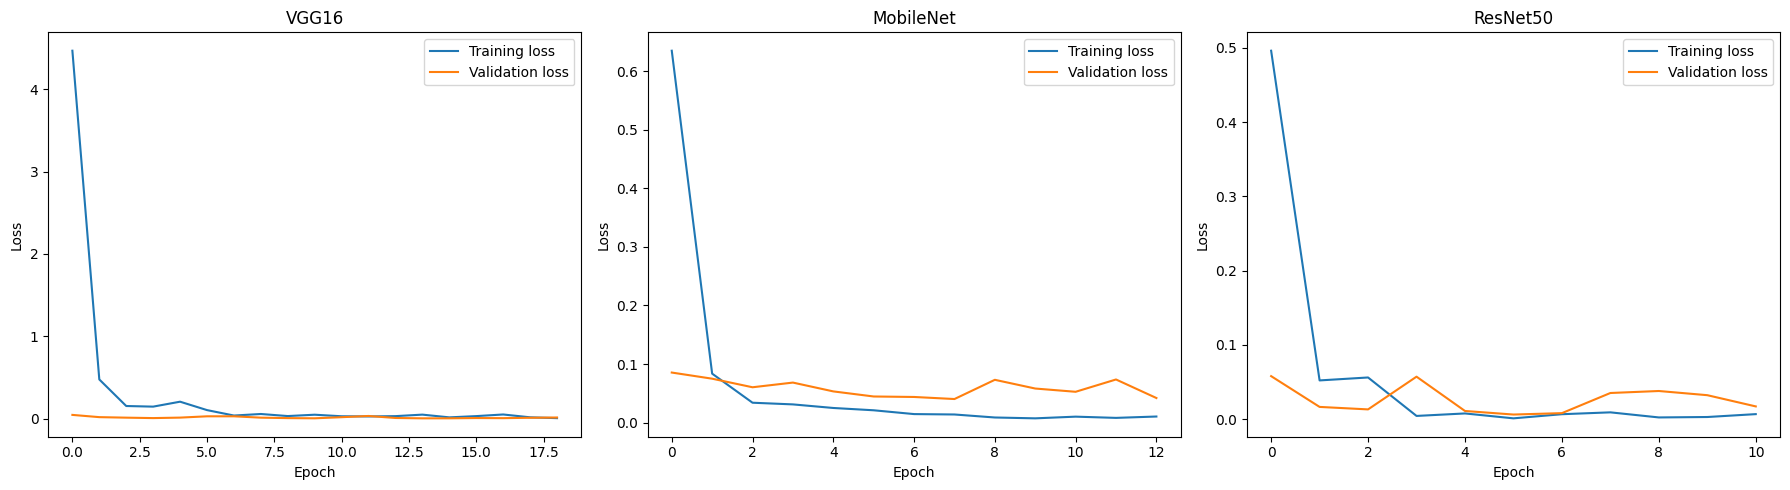

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (name, hist) in zip(ax, histories.items()):
    a.plot(hist.history['loss'], label='Training loss')
    a.plot(hist.history['val_loss'], label='Validation loss')
    a.set_title(name)
    a.set_xlabel('Epoch')
    a.set_ylabel('Loss')
    a.legend()
plt.tight_layout()
plt.show()

            Accuracy  Precision  Recall      F1
Custom CNN    0.3667     0.2175  0.3667  0.2323
VGG16         1.0000     1.0000  1.0000  1.0000
MobileNet     0.9889     0.9892  0.9889  0.9889
ResNet50      1.0000     1.0000  1.0000  1.0000


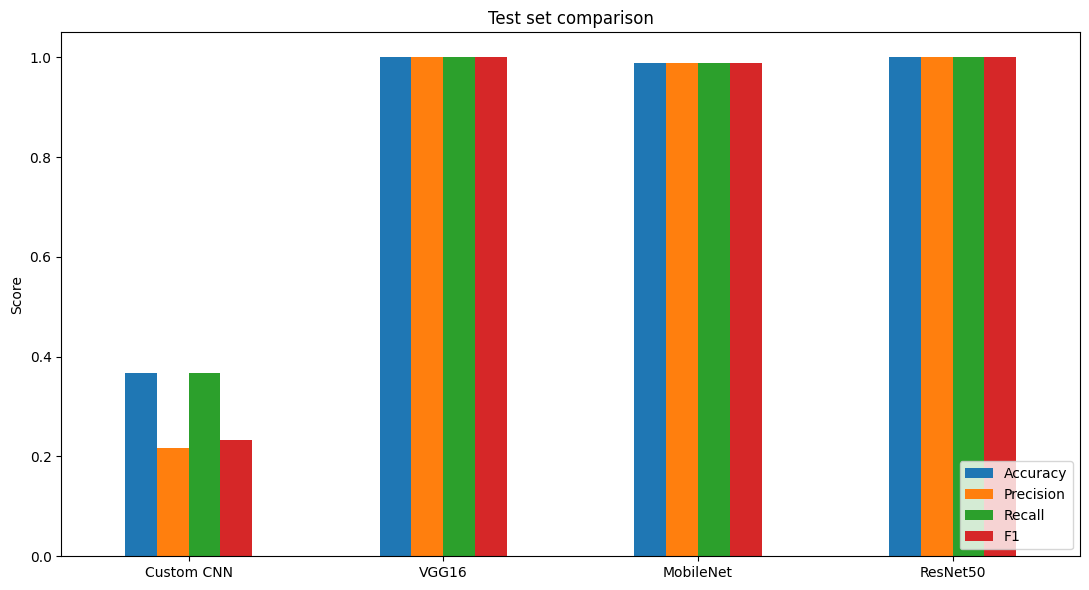

Best model by F1: VGG16 (1.0000)


In [12]:
import pandas as pd

df = pd.DataFrame(results).T.round(4)
print(df)

df.plot(kind='bar', figsize=(11, 6))
plt.ylim(0, 1.05)
plt.ylabel('Score')
plt.title('Test set comparison')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

best = df['F1'].idxmax()
print(f"Best model by F1: {best} ({df.loc[best, 'F1']:.4f})")